In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
import config
from src.utils import set_seed
set_seed(config.SEED)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.facecolor": "#F5F1E8", "figure.facecolor": "#F5F1E8", "axes.edgecolor": "#77766D",
                     "font.size": 10, "axes.titleweight": "bold"})
PALETTE = ["#344C3D", "#BD755A", "#C4A46A", "#899982", "#77766D", "#242723"]
sns.set_palette(PALETTE)
def note(txt):  # data-driven observation rendered as markdown
    display(Markdown("> **Observation.** " + txt))

# 04 — Classical Machine-Learning Experiments

Five classical algorithms on TF-IDF features for **sentence-role classification** (PubMed 20k RCT):

| Algorithm | Why it is included |
|---|---|
| Multinomial Naive Bayes | fastest probabilistic baseline for text counts |
| Logistic Regression | strong linear baseline, calibrated-ish probabilities, interpretable coefficients |
| Linear SVM | usually the best linear text classifier; no native probabilities |
| Random Forest | non-linear tree ensemble — tests whether feature interactions matter |
| XGBoost | gradient-boosted trees — the strongest tabular learner, a fair test on sparse text |

**Methodology (leakage prevention first)**

* Official **train / dev / test** split (abstract-disjoint, verified in notebook 01).
* TF-IDF is fitted *inside* a scikit-learn `Pipeline`, so within cross-validation it only ever sees the training fold.
* Hyper-parameters are tuned with **`GroupKFold` on `abstract_id`** — sentences of one abstract never straddle folds (adjacent sentences of one abstract are highly correlated, so plain stratified CV would be optimistic).
* The **test set is touched once**, after model selection.
* For *like-for-like* comparison with the transformer models (notebook 06), every model is additionally scored on one **fixed stratified 2,000-sentence test subset**.
* **Compute compromise (CPU laptop):** Naive Bayes, Logistic Regression and SVM use all 180,040 training sentences; Random Forest and XGBoost are trained on a **60,000-sentence stratified subset** (documented below), and Logistic Regression is also trained on that same subset so that "algorithm" is not confounded with "amount of data".

In [2]:
import time, json, joblib
import scipy.sparse as sp
import src.data as D
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from xgboost import XGBClassifier
from src.features import build_tfidf, position_features
from src.evaluation import classification_metrics, measure_latency_ms, softmax
from src.utils import save_json, update_json, load_json, timer

LAB = config.CLASS_LABELS
choice = load_json(config.ART_CLS / "preprocessing_choice.json", {"strategy": "clean", "ngram_range": [1, 2], "min_df": 2, "sublinear_tf": True, "max_features": 200000})
print("preprocessing choice from notebook 03:", {k: choice[k] for k in ("strategy", "ngram_range", "min_df", "sublinear_tf", "max_features")})
train, dev, test = (D.load_pubmed_rct(s) for s in ("train", "dev", "test"))
eval_sub = D.eval_subset(test)
(config.DATA_PROCESSED / "eval_subset.parquet").parent.mkdir(exist_ok=True, parents=True); eval_sub.to_parquet(config.DATA_PROCESSED / "eval_subset.parquet")
sub30m = D.stratified_subset(train, 30_000, config.SEED)

sub8 = D.stratified_subset(train, config.TRAIN_SUBSET_SENTENCES, config.SEED)
print(f"train {len(train):,} | dev {len(dev):,} | test {len(test):,} | shared test subset {len(eval_sub):,} | RF/XGB subset {len(sub30m):,} | transformer-matched subset {len(sub8):,}")
MODEL_DIR = config.ART_CLS / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
def tfidf(**kw):
    p = dict(strategy=choice["strategy"], ngram_range=tuple(choice["ngram_range"]), max_features=choice["max_features"], min_df=choice["min_df"], sublinear_tf=choice["sublinear_tf"]); p.update(kw)
    return build_tfidf(**p)

preprocessing choice from notebook 03: {'strategy': 'raw', 'ngram_range': [1, 2], 'min_df': 2, 'sublinear_tf': True, 'max_features': 200000}


train 180,040 | dev 30,212 | test 30,135 | shared test subset 2,000 | RF/XGB subset 30,000 | transformer-matched subset 3,001


## 1. Trivial baselines

Any model must beat *"always predict the most frequent class"*. We also report this macro-F1 so the reader sees how much of the score is real signal.

In [3]:
dummy = DummyClassifier(strategy="most_frequent").fit(train.text, train.label)
bm = classification_metrics(test.label, dummy.predict(test.text), LAB)
print(f"Majority-class baseline on test: accuracy={bm['accuracy']:.4f}  macro-F1={bm['f1_macro']:.4f}")

Majority-class baseline on test: accuracy=0.3284  macro-F1=0.0989


## 2. Hyper-parameter tuning with group-aware cross-validation

`RandomizedSearchCV` + `GroupKFold(3)` grouped by `abstract_id`, optimising **macro-F1**.
Cheap linear models are tuned on a 12k-sentence stratified subset; Random Forest and XGBoost (much costlier) on a 12k subset with fewer sampled configurations.
Tuning data come from the **training split only**.

In [4]:
def tune(name, est, space, data, n_iter, vec_kw=None):
    pipe = Pipeline([("tfidf", tfidf(**(vec_kw or {}))), ("clf", est)])
    y = data.label if name != "xgb" else data.label.map({l: i for i, l in enumerate(LAB)})
    cv = GroupKFold(n_splits=3)
    search = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring="f1_macro", cv=cv, random_state=config.SEED, n_jobs=1, refit=False, return_train_score=True)
    with timer() as t: search.fit(data.text, y, groups=data.abstract_id)
    r = pd.DataFrame(search.cv_results_)
    out = {"best_params": {k.replace("clf__", ""): v for k, v in search.best_params_.items()}, "cv_macro_f1": float(search.best_score_), "cv_std": float(r.loc[search.best_index_, "std_test_score"]),
           "train_macro_f1_at_best": float(r.loc[search.best_index_, "mean_train_score"]), "tuning_seconds": t.seconds, "n_candidates": len(r)}
    print(f"{name:4s} best CV macro-F1 {out['cv_macro_f1']:.4f} ± {out['cv_std']:.4f} (train {out['train_macro_f1_at_best']:.4f}) | {out['best_params']} | {t.seconds:.0f}s")
    return out, r
tune30 = D.stratified_subset(train, 12_000, config.SEED); tune15 = D.stratified_subset(train, 15_000, config.SEED)
TUNING = {}
TUNING["nb"], r_nb = tune("nb", MultinomialNB(), {"clf__alpha": [0.03, 0.1, 0.3, 1.0]}, tune30, 3)
TUNING["lr"], r_lr = tune("lr", LogisticRegression(max_iter=100), {"clf__C": [0.5, 1, 2, 5, 10, 20], "clf__class_weight": [None, "balanced"]}, tune30, 4)
TUNING["svm"], r_svm = tune("svm", LinearSVC(), {"clf__C": [0.1, 0.3, 1.0]}, tune30, 3)

nb   best CV macro-F1 0.6874 ± 0.0053 (train 0.9572) | {'alpha': 0.1} | 26s


lr   best CV macro-F1 0.7222 ± 0.0066 (train 0.9976) | {'class_weight': 'balanced', 'C': 10} | 51s


svm  best CV macro-F1 0.7204 ± 0.0057 (train 0.9631) | {'C': 0.3} | 16s


In [5]:
TUNING["rf"], r_rf = tune("rf", RandomForestClassifier(n_estimators=80, n_jobs=4, random_state=config.SEED),
                           {"clf__min_samples_leaf": [1, 2, 4], "clf__max_features": ["sqrt", 0.02], "clf__max_depth": [None, 60]}, tune15, 2, vec_kw=dict(max_features=20_000))
TUNING["xgb"], r_xgb = tune("xgb", XGBClassifier(tree_method="hist", n_jobs=4, random_state=config.SEED, objective="multi:softprob"),
                             {"clf__max_depth": [4, 6], "clf__learning_rate": [0.1, 0.2], "clf__n_estimators": [100, 150], "clf__subsample": [0.8, 1.0]}, tune15, 2, vec_kw=dict(max_features=20_000))
tdf = pd.DataFrame({k: {"cv macro-F1": v["cv_macro_f1"], "cv std": v["cv_std"], "train macro-F1": v["train_macro_f1_at_best"], "gap": v["train_macro_f1_at_best"] - v["cv_macro_f1"], "tuning s": v["tuning_seconds"]} for k, v in TUNING.items()}).T
display(tdf.round(4))
note(f"Train–CV gaps (overfitting indicator): " + ", ".join(f"**{k}** {v:+.3f}" for k, v in tdf["gap"].items()) + ". "
     "Tree ensembles typically show the largest gap because they can memorise rare n-gram combinations; regularised linear models generalise more smoothly.")

rf   best CV macro-F1 0.6682 ± 0.0016 (train 0.9857) | {'min_samples_leaf': 1, 'max_features': 0.02, 'max_depth': 60} | 42s


xgb  best CV macro-F1 0.6699 ± 0.0058 (train 0.7629) | {'subsample': 0.8, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.1} | 342s


,cv macro-F1,cv std,train macro-F1,gap,tuning s
nb,0.6874,0.0053,0.9572,0.2698,26.4708
lr,0.7222,0.0066,0.9976,0.2754,50.9745
svm,0.7204,0.0057,0.9631,0.2427,16.3537
rf,0.6682,0.0016,0.9857,0.3174,42.1732
xgb,0.6699,0.0058,0.7629,0.0930,342.0605


> **Observation.** Train–CV gaps (overfitting indicator): **nb** +0.270, **lr** +0.275, **svm** +0.243, **rf** +0.317, **xgb** +0.093. Tree ensembles typically show the largest gap because they can memorise rare n-gram combinations; regularised linear models generalise more smoothly.

## 3. Final training and evaluation

Refit each model with its best hyper-parameters, then evaluate on the **full dev set**, the **full test set** and the **shared 2k test subset**.
Recorded for every model: macro/weighted precision/recall/F1, accuracy, training time, inference latency (ms per sentence, *including* preprocessing + vectorisation),
serialized model size, and — for the deployed app — the artifact itself.

In [6]:
def fit_eval(name, est, data, vec_kw=None, label="", save=True, int_labels=False):
    vec = tfidf(**(vec_kw or {}))
    pipe = Pipeline([("tfidf", vec), ("clf", est)])
    y = data.label.map({l: i for i, l in enumerate(LAB)}) if int_labels else data.label
    with timer() as t: pipe.fit(data.text, y)
    inv = (lambda a: np.array([LAB[i] for i in a])) if int_labels else (lambda a: a)
    res = {"kind": "classical", "label": label or name, "train_n": int(len(data)), "train_seconds": t.seconds}
    res["dev"] = classification_metrics(dev.label, inv(pipe.predict(dev.text)), LAB)
    res["test_full"] = classification_metrics(test.label, inv(pipe.predict(test.text)), LAB)
    sub_pred = inv(pipe.predict(eval_sub.text)); m = classification_metrics(eval_sub.label, sub_pred, LAB)
    res.update({k: v for k, v in m.items()})                      # headline = shared test subset
    sample = eval_sub.text.tolist()[:1000]
    res["latency_ms"] = measure_latency_ms(lambda b: pipe.predict(b), sample, repeats=3)
    path = MODEL_DIR / f"{name}.joblib"
    joblib.dump(pipe, path, compress=3); res["model_mb"] = path.stat().st_size / 1e6
    clf = pipe.steps[-1][1]; res["n_features"] = int(len(vec.vocabulary_))
    res["best_params"] = TUNING.get(name.split("_")[-1], {}).get("best_params", {})
    # per-sample probabilities on the shared subset (for calibration / error analysis, notebook 09)
    if hasattr(clf, "predict_proba"): P = pipe.predict_proba(eval_sub.text); P = P if int_labels else P[:, [list(clf.classes_).index(l) for l in LAB]]
    else: P = softmax(pipe.decision_function(eval_sub.text))[:, [list(clf.classes_).index(l) for l in LAB]]
    np.savez_compressed(config.ART_EVAL / f"preds_{name}.npz", probs=P.astype("float32"), y=eval_sub.label.map({l: i for i, l in enumerate(LAB)}).values)
    update_json(config.ART_CLS / "metrics.json", name, res)
    print(f"{name:12s} train={t.seconds:7.1f}s | test_full macro-F1={res['test_full']['f1_macro']:.4f} acc={res['test_full']['accuracy']:.4f} | subset macro-F1={m['f1_macro']:.4f} | {res['latency_ms']:.2f} ms/sent | {res['model_mb']:.1f} MB")
    return pipe, res
(config.ART_EVAL).mkdir(parents=True, exist_ok=True)
bp = TUNING
pipes, R = {}, {}
pipes["tfidf_nb"], R["tfidf_nb"] = fit_eval("tfidf_nb", MultinomialNB(**bp["nb"]["best_params"]), train, label="Naive Bayes")
pipes["tfidf_lr"], R["tfidf_lr"] = fit_eval("tfidf_lr", LogisticRegression(max_iter=150, **bp["lr"]["best_params"]), train, label="Logistic Regression")
pipes["tfidf_svm"], R["tfidf_svm"] = fit_eval("tfidf_svm", LinearSVC(**bp["svm"]["best_params"]), train, label="Linear SVM")

tfidf_nb     train=   35.0s | test_full macro-F1=0.7371 acc=0.8043 | subset macro-F1=0.7430 | 0.17 ms/sent | 10.2 MB


tfidf_lr     train=  143.1s | test_full macro-F1=0.7608 acc=0.8223 | subset macro-F1=0.7706 | 0.10 ms/sent | 6.2 MB


tfidf_svm    train=   47.8s | test_full macro-F1=0.7712 acc=0.8331 | subset macro-F1=0.7889 | 0.13 ms/sent | 9.3 MB


In [7]:
pipes["tfidf_rf"], R["tfidf_rf"] = fit_eval("tfidf_rf", RandomForestClassifier(n_estimators=150, n_jobs=4, random_state=config.SEED, **bp["rf"]["best_params"]), sub30m, vec_kw=dict(max_features=20_000), label="Random Forest (30k)")
pipes["tfidf_xgb"], R["tfidf_xgb"] = fit_eval("tfidf_xgb", XGBClassifier(tree_method="hist", n_jobs=4, random_state=config.SEED, objective="multi:softprob", **bp["xgb"]["best_params"]), sub30m, vec_kw=dict(max_features=20_000), label="XGBoost (30k)", int_labels=True)
# like-for-like references: LR trained on the same 30k and 8k subsets used elsewhere
_, R["tfidf_lr_30k"] = fit_eval("tfidf_lr_30k", LogisticRegression(max_iter=150, **bp["lr"]["best_params"]), sub30m, label="Logistic Regression (30k)")
_, R["tfidf_lr_8k"] = fit_eval("tfidf_lr_8k", LogisticRegression(max_iter=150, **bp["lr"]["best_params"]), sub8, label=f"Logistic Regression ({len(sub8)//1000}k, transformer-matched)")
update_json(config.ART_CLS / "tuning.json", "classical", TUNING)

tfidf_rf     train=   97.1s | test_full macro-F1=0.6827 acc=0.7528 | subset macro-F1=0.6936 | 0.20 ms/sent | 31.8 MB


tfidf_xgb    train=  154.9s | test_full macro-F1=0.6689 acc=0.7337 | subset macro-F1=0.6895 | 0.12 ms/sent | 0.4 MB


tfidf_lr_30k train=   37.0s | test_full macro-F1=0.7357 acc=0.8014 | subset macro-F1=0.7469 | 0.13 ms/sent | 2.7 MB


tfidf_lr_8k  train=    3.1s | test_full macro-F1=0.6777 acc=0.7468 | subset macro-F1=0.6927 | 0.11 ms/sent | 0.3 MB


## 4. Results

In [8]:
tbl = pd.DataFrame({k: {"model": v["label"], "train n": v["train_n"], "accuracy (test)": v["test_full"]["accuracy"], "macro-F1 (test)": v["test_full"]["f1_macro"], "weighted-F1 (test)": v["test_full"]["f1_weighted"],
                          "macro-P": v["test_full"]["precision_macro"], "macro-R": v["test_full"]["recall_macro"], "macro-F1 (2k subset)": v["f1_macro"], "dev macro-F1": v["dev"]["f1_macro"],
                          "train s": v["train_seconds"], "ms/sent": v["latency_ms"], "MB": v["model_mb"]} for k, v in R.items()}).T.set_index("model")
tbl = tbl.sort_values("macro-F1 (test)", ascending=False)
tbl.style.format({c: "{:.4f}" for c in tbl.columns if "F1" in c or c in ("accuracy (test)", "macro-P", "macro-R")} | {"train s": "{:.1f}", "ms/sent": "{:.3f}", "MB": "{:.1f}"}).background_gradient(subset=["macro-F1 (test)"], cmap="YlGn")

,train n,accuracy (test),macro-F1 (test),weighted-F1 (test),macro-P,macro-R,macro-F1 (2k subset),dev macro-F1,train s,ms/sent,MB
model,,,,,,,,,,,
Linear SVM,180040,0.8331,0.7712,0.8302,0.7854,0.7616,0.7889,0.7808,47.8,0.127,9.3
Logistic Regression,180040,0.8223,0.7608,0.8231,0.7590,0.7632,0.7706,0.7698,143.1,0.097,6.2
Naive Bayes,180040,0.8043,0.7371,0.8020,0.7473,0.7317,0.7430,0.7422,35.0,0.169,10.2
Logistic Regression (30k),30000,0.8014,0.7357,0.8012,0.7365,0.7358,0.7469,0.7429,37.0,0.130,2.7
Random Forest (30k),30000,0.7528,0.6827,0.7457,0.7205,0.6640,0.6936,0.6903,97.1,0.196,31.8
"Logistic Regression (3k, transformer-matched)",3001,0.7468,0.6777,0.7460,0.6815,0.6758,0.6927,0.6868,3.1,0.114,0.3
XGBoost (30k),30000,0.7337,0.6689,0.7292,0.6973,0.6541,0.6895,0.6775,154.9,0.118,0.4


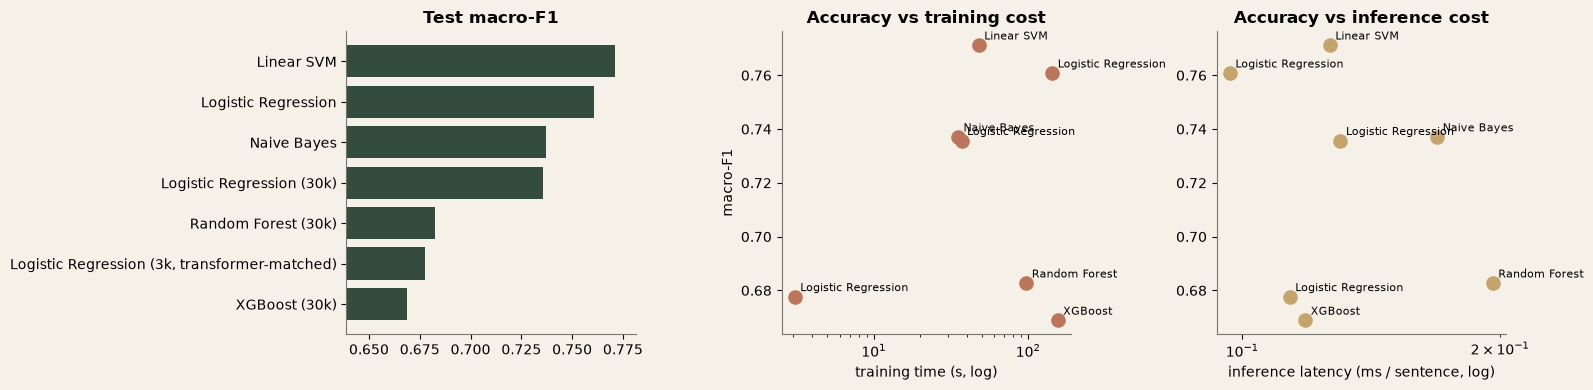

> **Observation.** Best classical model on the full test set: **Linear SVM** (macro-F1 0.7712, accuracy 0.8331); the majority-class baseline scores macro-F1 0.0989. On the *same 30k subset*, LR reaches 0.7357 while RF reaches 0.6827 and XGBoost 0.6689, so any gap to those tree models is attributable to the *algorithm*, not to training-set size. The 2k-subset scores track the full-test scores within 0.021 macro-F1, which validates the subset as a fair proxy.

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t = tbl.sort_values("macro-F1 (test)"); axes[0].barh(t.index, t["macro-F1 (test)"], color=PALETTE[0]); axes[0].set_xlim(t["macro-F1 (test)"].min() - .03, t["macro-F1 (test)"].max() + .01); axes[0].set_title("Test macro-F1")
axes[1].scatter(tbl["train s"], tbl["macro-F1 (test)"], s=90, color=PALETTE[1]); [axes[1].annotate(i.split(" (")[0], (r["train s"], r["macro-F1 (test)"]), fontsize=8, xytext=(4, 4), textcoords="offset points") for i, r in tbl.iterrows()]
axes[1].set_xscale("log"); axes[1].set_xlabel("training time (s, log)"); axes[1].set_ylabel("macro-F1"); axes[1].set_title("Accuracy vs training cost")
axes[2].scatter(tbl["ms/sent"], tbl["macro-F1 (test)"], s=90, color=PALETTE[2]); [axes[2].annotate(i.split(" (")[0], (r["ms/sent"], r["macro-F1 (test)"]), fontsize=8, xytext=(4, 4), textcoords="offset points") for i, r in tbl.iterrows()]
axes[2].set_xscale("log"); axes[2].set_xlabel("inference latency (ms / sentence, log)"); axes[2].set_title("Accuracy vs inference cost")
plt.tight_layout(); plt.show()
b = tbl.iloc[0]; mb = bm["f1_macro"]
note(f"Best classical model on the full test set: **{tbl.index[0]}** (macro-F1 {b['macro-F1 (test)']:.4f}, accuracy {b['accuracy (test)']:.4f}); the majority-class baseline scores macro-F1 {mb:.4f}. "
     f"On the *same 30k subset*, LR reaches {R['tfidf_lr_30k']['test_full']['f1_macro']:.4f} while RF reaches {R['tfidf_rf']['test_full']['f1_macro']:.4f} and XGBoost {R['tfidf_xgb']['test_full']['f1_macro']:.4f}, "
     f"so any gap to those tree models is attributable to the *algorithm*, not to training-set size. The 2k-subset scores track the full-test scores within "
     f"{max(abs(v['f1_macro'] - v['test_full']['f1_macro']) for v in R.values()):.3f} macro-F1, which validates the subset as a fair proxy.")

### 4.1 Confusion matrices (row-normalised, full test set)

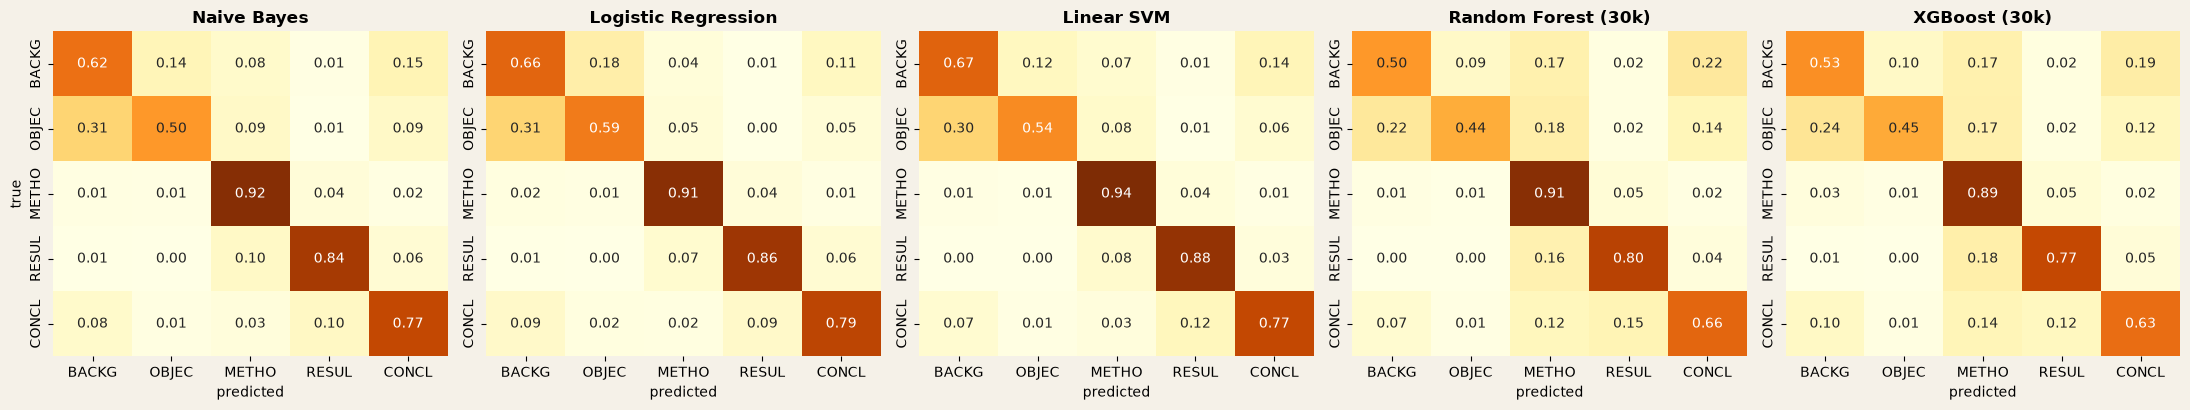

> **Observation.** For the best model (Linear SVM) the largest confusions are true **OBJECTIVE** → predicted **BACKGROUND** (30.5%); true **BACKGROUND** → predicted **CONCLUSIONS** (13.7%); true **CONCLUSIONS** → predicted **RESULTS** (12.4%). Confusions between *adjacent* rhetorical roles are linguistically natural: the same sentence can be motivation (BACKGROUND) and aim (OBJECTIVE), or a finding (RESULTS) phrased as an interpretation (CONCLUSIONS).

In [10]:
from src.evaluation import classification_metrics as cm_
show = ["tfidf_nb", "tfidf_lr", "tfidf_svm", "tfidf_rf", "tfidf_xgb"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, k in zip(axes, show):
    cmx = np.array(R[k]["test_full"]["confusion_matrix"]); cmn = cmx / cmx.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="YlOrBr", xticklabels=[l[:5] for l in LAB], yticklabels=[l[:5] for l in LAB], cbar=False, ax=ax, vmin=0, vmax=1)
    ax.set_title(R[k]["label"]); ax.set_xlabel("predicted"); ax.set_ylabel("true" if k == show[0] else "")
plt.tight_layout(); plt.show()
bestk = max(show, key=lambda k: R[k]["test_full"]["f1_macro"]); cmn = np.array(R[bestk]["test_full"]["confusion_matrix"]); cmn = cmn / cmn.sum(1, keepdims=True)
off = [(LAB[i], LAB[j], cmn[i, j]) for i in range(5) for j in range(5) if i != j]; off.sort(key=lambda x: -x[2])
note(f"For the best model ({R[bestk]['label']}) the largest confusions are " + "; ".join(f"true **{a}** → predicted **{b}** ({v:.1%})" for a, b, v in off[:3]) + ". "
     "Confusions between *adjacent* rhetorical roles are linguistically natural: the same sentence can be motivation (BACKGROUND) and aim (OBJECTIVE), or a finding (RESULTS) phrased as an interpretation (CONCLUSIONS).")

### 4.2 Per-class report of the best classical model

In [11]:
pc = pd.DataFrame(R[bestk]["test_full"]["per_class"]).T[["precision", "recall", "f1", "support"]]
display(pc.round(4))
worst = pc.f1.idxmin()
note(f"The weakest class is **{worst}** (F1 {pc.f1.min():.3f}); the strongest is **{pc.f1.idxmax()}** (F1 {pc.f1.max():.3f}). "
     f"Minority classes are the hardest, as expected from the 4:1 imbalance, which is why accuracy alone would overstate quality.")

,precision,recall,f1,support
BACKGROUND,0.6829,0.6708,0.6768,3621.0
OBJECTIVE,0.7022,0.5418,0.6117,2333.0
METHODS,0.8764,0.9385,0.9064,9897.0
RESULTS,0.8959,0.8847,0.8902,9713.0
CONCLUSIONS,0.7696,0.7725,0.7710,4571.0


> **Observation.** The weakest class is **OBJECTIVE** (F1 0.612); the strongest is **METHODS** (F1 0.906). Minority classes are the hardest, as expected from the 4:1 imbalance, which is why accuracy alone would overstate quality.

## 5. Ablation A — class weighting

During tuning, `class_weight` was one of LR's sampled hyper-parameters. We directly compare the two settings on dev with otherwise identical settings (30k subset).

In [12]:
rows = []
for cw in [None, "balanced"]:
    pipe = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=bp["lr"]["best_params"].get("C", 5), max_iter=150, class_weight=cw))]).fit(tune30.text, tune30.label)
    m = classification_metrics(dev.label, pipe.predict(dev.text), LAB)
    rows.append({"class_weight": str(cw), "accuracy": m["accuracy"], "macro_f1": m["f1_macro"], "OBJECTIVE_recall": m["per_class"]["OBJECTIVE"]["recall"], "BACKGROUND_recall": m["per_class"]["BACKGROUND"]["recall"]})
cw_df = pd.DataFrame(rows).set_index("class_weight"); display(cw_df.round(4))
note("Balanced weights trade a little accuracy for higher recall on the minority classes (compare the OBJECTIVE and BACKGROUND recall columns), which is the expected behaviour; "
     "the macro-F1 column shows whether that trade is worthwhile on this data.")

,accuracy,macro_f1,OBJECTIVE_recall,BACKGROUND_recall
class_weight,,,,
None,0.7944,0.7233,0.4912,0.5831
balanced,0.7917,0.7244,0.5442,0.5909


> **Observation.** Balanced weights trade a little accuracy for higher recall on the minority classes (compare the OBJECTIVE and BACKGROUND recall columns), which is the expected behaviour; the macro-F1 column shows whether that trade is worthwhile on this data.

## 6. Ablation B — does sentence *position* help? (context-free vs position-aware)

Notebook 02 showed that relative position inside the abstract is extremely informative. We add three position features (relative index, is-first, is-last) to the TF-IDF matrix.
This is **not** used for the main benchmark (the transformers see a sentence in isolation, and a user may paste a single sentence), but it quantifies how much context-free models leave on the table.

In [13]:
vec = tfidf(); Xtr = vec.fit_transform(train.text); Xte = vec.transform(test.text)
Ptr, Pte = position_features(train.sent_idx, train.n_sents), position_features(test.sent_idx, test.n_sents)
C = bp["lr"]["best_params"].get("C", 5)
rows = {}
for name, (A, B) in {"text only": (Xtr, Xte), "position only": (sp.csr_matrix(Ptr), sp.csr_matrix(Pte)), "text + position": (sp.hstack([Xtr, sp.csr_matrix(Ptr * 3)]).tocsr(), sp.hstack([Xte, sp.csr_matrix(Pte * 3)]).tocsr())}.items():
    clf = LogisticRegression(C=C, max_iter=150).fit(A, train.label); m = classification_metrics(test.label, clf.predict(B), LAB)
    rows[name] = {"accuracy": m["accuracy"], "macro_f1": m["f1_macro"]}
pos_df = pd.DataFrame(rows).T; display(pos_df.round(4))
update_json(config.ART_CLS / "ablations.json", "position_features", pos_df.round(4).to_dict("index"))
note(f"Position alone reaches macro-F1 {pos_df.loc['position only', 'macro_f1']:.3f}; text alone {pos_df.loc['text only', 'macro_f1']:.3f}; combining them gives {pos_df.loc['text + position', 'macro_f1']:.3f} "
     f"(Δ {pos_df.loc['text + position', 'macro_f1'] - pos_df.loc['text only', 'macro_f1']:+.3f} over text only). Sequential context is a major, untapped information source "
     f"for sentence-only models — a clear *future-work* direction (sequential sentence models such as BiLSTM-CRF or hierarchical transformers).")

,accuracy,macro_f1
text only,0.8231,0.7595
position only,0.6781,0.5538
text + position,0.8772,0.8251


> **Observation.** Position alone reaches macro-F1 0.554; text alone 0.759; combining them gives 0.825 (Δ +0.066 over text only). Sequential context is a major, untapped information source for sentence-only models — a clear *future-work* direction (sequential sentence models such as BiLSTM-CRF or hierarchical transformers).

## 7. Learning curve — how much data does a linear model need?

This answers a practical question for the transformer notebook: if DistilBERT sees only 8k sentences, how does that compare with a linear model given the same budget? Dev macro-F1 versus training-set size (same tuned LR).

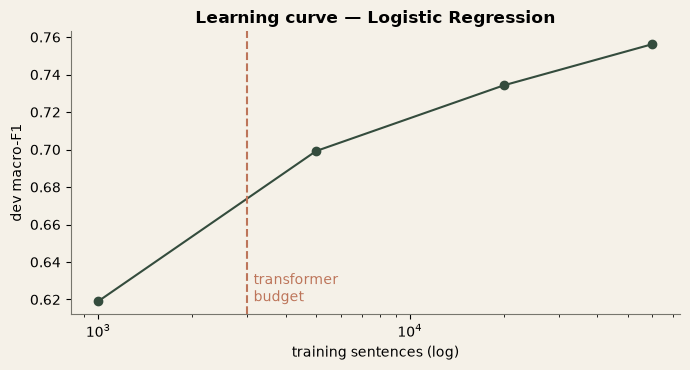

> **Observation.** Macro-F1 rises from 0.619 (1k sentences) to 0.756 (60,000); the last step (30k → full) adds +0.0220. At the transformer budget of 3,001 sentences LR reaches ≈0.659, which is the right reference point for judging the CPU-limited transformer results.

In [14]:
sizes = [1000, 5000, 20000, 60000]
lc = []
for n in sizes:
    d = D.stratified_subset(train, n, config.SEED)
    pipe = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=C, max_iter=150))]).fit(d.text, d.label)
    m = classification_metrics(dev.label, pipe.predict(dev.text), LAB); lc.append({"n_train": n, "dev_macro_f1": m["f1_macro"], "dev_acc": m["accuracy"]})
lc = pd.DataFrame(lc); fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(lc.n_train, lc.dev_macro_f1, "o-", color=PALETTE[0]); ax.set_xscale("log"); ax.set_xlabel("training sentences (log)"); ax.set_ylabel("dev macro-F1"); ax.set_title("Learning curve — Logistic Regression")
ax.axvline(len(sub8), color=PALETTE[1], ls="--"); ax.text(len(sub8) * 1.05, lc.dev_macro_f1.min(), "transformer\nbudget", color=PALETTE[1])
plt.tight_layout(); plt.show(); update_json(config.ART_CLS / "ablations.json", "learning_curve_lr", lc.round(4).to_dict("records"))
note(f"Macro-F1 rises from {lc.dev_macro_f1.iloc[0]:.3f} (1k sentences) to {lc.dev_macro_f1.iloc[-1]:.3f} ({lc.n_train.iloc[-1]:,}); the last step (30k → full) adds {lc.dev_macro_f1.iloc[-1] - lc.dev_macro_f1.iloc[-2]:+.4f}. "
     f"At the transformer budget of {len(sub8):,} sentences LR reaches ≈{np.interp(len(sub8), lc.n_train, lc.dev_macro_f1):.3f}, which is the right reference point for judging the CPU-limited transformer results.")

## 8. Most informative terms (global view)

For the best linear model: highest-weight TF-IDF features per class. Weights describe **association in this dataset, not causation**.

In [15]:
lrp = pipes["tfidf_lr"]; vocab = np.array(lrp.named_steps["tfidf"].get_feature_names_out()); coef = lrp.named_steps["clf"].coef_; classes = list(lrp.named_steps["clf"].classes_)
top = {l: list(vocab[np.argsort(-coef[classes.index(l)])[:10]]) for l in LAB}
pd.DataFrame(top, index=range(1, 11))

,BACKGROUND,OBJECTIVE,METHODS,RESULTS,CONCLUSIONS
1,was to,compare,were,was,should
2,),whether,was,significantly,] ;
3,is,(,will,were,) .
4,aimed to,evaluate,included,p,improved
5,has,to,received,( p,( clinicaltrials.gov
6,.,to investigate,", number",p =,may
7,clinicaltrials.gov,to compare,study is,%,studies are
8,registered,to test,we used,showed,significantly
9,are,to evaluate,provides class,mean,can
10,(,to determine,then,had,improves


## Conclusions

* Group-aware CV, tuning, and a single final test evaluation were used; tuning curves, train–CV gaps and a shared 2k test subset make the comparison transparent.
* The ranking of the five algorithms, their train/inference costs and the per-class weaknesses are printed above (numbers are produced by the run, not typed in).
* Position features show that a large share of the remaining error of sentence-only models is *context*, not vocabulary.
* All models, metrics (`artifacts/classification/metrics.json`) and subset predictions (`artifacts/evaluation/preds_*.npz`) are persisted for the benchmark (notebook 10), explainability (notebook 09) and the Flask app.